In [17]:
import open_clip
import torch
from PIL import Image
from matplotlib import pyplot as plt

from homework_3.functions import parse_img, get_cache, api_response_to_tensor

In [18]:
class ClipModel(torch.nn.Module):
    def __init__(self, head1_weights, head2_weights, model_name="ViT-B-32", pretrained="laion2b_s34b_b79k"):
        super().__init__()
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.clip_backbone, _, self.preprocess = open_clip.create_model_and_transforms(model_name=model_name,
                                                                                       pretrained=pretrained)
        for p in self.clip_backbone.parameters():
            p.requires_grad = False
        self.clip_backbone.eval()
        self.tokenizer = open_clip.get_tokenizer('ViT-B-32')

        self.concept_labels = ["class1", "class2", "class3", "class4"]

        self.concept1_tokens = self.tokenizer(self.concept_labels[:2])
        self.concept2_tokens = self.tokenizer(self.concept_labels[2:])

        self.concept1_class_features = self.clip_backbone.encode_text(self.concept1_tokens)
        self.concept1_class_features /= self.concept1_class_features.norm(dim=-1, keepdim=True)
        self.concept1_class_features = self.concept1_class_features.to(self.device)

        self.concept2_class_features = self.clip_backbone.encode_text(self.concept2_tokens)
        self.concept2_class_features /= self.concept2_class_features.norm(dim=-1, keepdim=True)
        self.concept2_class_features = self.concept2_class_features.to(self.device)

        self.head_concept1 = torch.nn.Linear(self.clip_backbone.visual.output_dim,
                                             self.clip_backbone.visual.output_dim)
        self.head_concept2 = torch.nn.Linear(self.clip_backbone.visual.output_dim,
                                             self.clip_backbone.visual.output_dim)

        self.clip_backbone.to(self.device)
        self.head_concept1.to(self.device)
        self.head_concept2.to(self.device)

        self._load_heads(head1_weights, head2_weights)

    def _load_heads(self, head1_weights, head2_weights):
        try:
            self.head_concept1.load_state_dict(
                torch.load(head1_weights, map_location=self.device))
        except FileNotFoundError:
            exit("Could not find the provided filepath for loading head weights.\n"
                 f"Make sure {head1_weights} exists.")
        try:
            self.head_concept2.load_state_dict(
                torch.load(head2_weights, map_location=self.device))
        except FileNotFoundError:
            exit("Could not find the provided filepath for loading head weights.\n"
                 f"Make sure {head2_weights} exists.")

    def forward(self, images: torch.Tensor, head=True) -> torch.Tensor:
        with torch.no_grad():
            image_features = self.clip_backbone.encode_image(images)

            concept1_features = self.head_concept1(image_features)
            concept2_features = self.head_concept2(image_features)

            concept1_features /= concept1_features.norm(dim=-1, keepdim=True)
            concept2_features /= concept2_features.norm(dim=-1, keepdim=True)

            concept1_similarity = (100.0 * concept1_features @ self.concept1_class_features.T).softmax(dim=-1)
            concept2_similarity = (100.0 * concept2_features @ self.concept2_class_features.T).softmax(dim=-1)
            return torch.cat((concept1_similarity, concept2_similarity), dim=1)

Image white.png
Hash: bb76d5f08e95ce524a1bd80f626622a0
API results:	tensor([0.0970, 0.9030, 0.8605, 0.1395])
Model results:	tensor([[0.0025, 0.9975, 0.9951, 0.0049]], device='cuda:0')


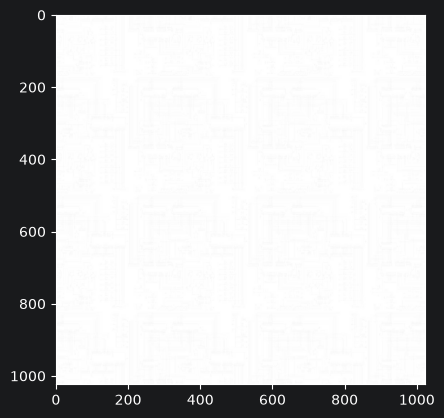

In [19]:
WEIGHTS_HEAD1 = "../weights/concept1_25_2.pth"
WEIGHTS_HEAD2 = "../weights/concept2_25_2.pth"

IMG_DIR = "../img"

clip_model = ClipModel(WEIGHTS_HEAD1, WEIGHTS_HEAD2)

image_file = "white.png"

try:
    raw_img = Image.open(f"{IMG_DIR}/{image_file}")
except FileNotFoundError:
    exit("File not found")

_, img_hash = parse_img(raw_img)
api_response = get_cache(img_hash)
# We are only testing results from cache here
# noinspection bad-argument-type
label = api_response_to_tensor(api_response)
preprocessed_image = clip_model.preprocess(raw_img).unsqueeze(0).cuda()

output = clip_model(preprocessed_image)

plt.imshow(raw_img)

print(f"Image {image_file}\n"
      f"Hash: {img_hash}\n"
      f"API results:\t{label}\n"
      f"Model results:\t{output}")